In [24]:
%pip install xgboost lightgbm

Note: you may need to restart the kernel to use updated packages.


In [25]:
# Import libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Regression libraries imported successfully")

Regression libraries imported successfully


In [26]:
from sklearn.ensemble import GradientBoostingRegressor

from xgboost import XGBRegressor

from lightgbm import LGBMRegressor

print("Additional regression libraries imported successfully")

Additional regression libraries imported successfully


In [27]:
# Loading the feature-engineered dataset

df = pd.read_csv(
    "data/charging_records_featured.csv"
)

print("Dataset loaded successfully")

print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully
Dataset shape: (72826, 20)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand,CalculatedDuration,Hour,DayOfWeek,Month,Year,IsWeekend,TimeOfDay
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:00,2022-09-15 23:59:00,185,20.36,185.0,20,3,9,2022,0,Evening
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:00,2022-09-14 21:31:00,90,10.19,90.0,20,2,9,2022,0,Evening
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:00,2022-09-14 19:54:00,60,6.78,60.0,18,2,9,2022,0,Evening
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,00:16:42,2022-09-29 18:32:00,2022-09-30 00:16:00,344,37.65,344.0,18,3,9,2022,0,Evening
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,00:30:14,2022-09-25 19:30:00,2022-09-26 00:30:00,300,33.81,300.0,19,6,9,2022,1,Evening


In [28]:
# Selecting the input features-----We need to tell Python which columns should be used to make predictions.

features = [
    "ChargerCompany",
    "Location",
    "ChargerType",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend"
]

target = "Demand"

In [29]:
# Prepare X and y
    # X represents input features
    # Y represents the target variable


X = df[features]

y = df[target]

print("Input features shape:", X.shape)

print("Target variable shape:", y.shape)

Input features shape: (72826, 7)
Target variable shape: (72826,)


In [30]:
# Identify categorical and numerical columns
    # Machine learning models need numbers as inputs.
    # However, Location contains text such as hotel, apartment and other categories.
    # We need to convert categorical columns into numerical representations.


categorical_features = [
    "ChargerCompany",
    "Location",
    "ChargerType"
]

numerical_features = [
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend"
]

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['ChargerCompany', 'Location', 'ChargerType']

Numerical features:
['Hour', 'DayOfWeek', 'Month', 'IsWeekend']


In [31]:
# Create the preprocessing pipeline
        # Preprocessing means converting the raw input data into a suitable format before training the model.
            # Categorical columns will use One-Hot Encoding.
            # Numerical columns will use Standard Scaling.

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

numerical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_transformer,
            categorical_features
        ),
        (
            "numerical",
            numerical_transformer,
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully")


Preprocessing pipeline created successfully


In [32]:
# Split the data into training and testing datasets (Train-Test Split)


model_df = df[
    features + ["StartDatetime", target]
].copy()

model_df["StartDatetime"] = pd.to_datetime(
    model_df["StartDatetime"],
    errors="coerce"
)

model_df = (
    model_df
    .dropna(subset=features + ["StartDatetime", target])
    .sort_values("StartDatetime")
    .reset_index(drop=True)
)

split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index].copy()

test_df = model_df.iloc[split_index:].copy()

X_train = train_df[features]
X_test = test_df[features]

y_train = train_df[target]
y_test = test_df[target]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print(
    "Training date range:",
    train_df["StartDatetime"].min(),
    "to",
    train_df["StartDatetime"].max()
)

print(
    "Testing date range:",
    test_df["StartDatetime"].min(),
    "to",
    test_df["StartDatetime"].max()
)


Training records: 58260
Testing records: 14566
Training date range: 2021-09-30 17:14:00 to 2022-07-30 19:09:00
Testing date range: 2022-07-30 19:09:00 to 2022-09-30 23:11:00


In [33]:
# Create the six regression models

models = {

    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),
    
    "XGBoost": XGBRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=5,
        random_state=42,
        n_jobs=-1,
        objective="reg:squarederror"
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=5,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

}

print("Total regression models:", len(models))

Total regression models: 6


In [34]:
# Train all six regression models


trained_pipelines = {}

results = []

for name, model in models.items():

    print("\nTraining:", name)

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    # Train model
    pipeline.fit(X_train, y_train)

    # Predict test data
    predictions = pipeline.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(
        y_test,
        predictions
    )

    mse = mean_squared_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test,
        predictions
    )

    results.append({

        "Model": name,

        "MAE": mae,

        "MSE": mse,

        "RMSE": rmse,

        "R2": r2

    })

    trained_pipelines[name] = pipeline

    print(name, "completed successfully")

print("\nAll six regression models trained!")


Training: Linear Regression
Linear Regression completed successfully

Training: Decision Tree
Decision Tree completed successfully

Training: Random Forest
Random Forest completed successfully

Training: Gradient Boosting
Gradient Boosting completed successfully

Training: XGBoost
XGBoost completed successfully

Training: LightGBM
LightGBM completed successfully

All six regression models trained!


In [35]:
# Compare model performance

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
)

display(results_df)

,Model,MAE,MSE,RMSE,R2
5,LightGBM,10.012977,171.612987,13.100114,0.113747
4,XGBoost,10.032374,172.961369,13.151478,0.106784
3,Gradient Boosting,10.101066,173.692971,13.179263,0.103006
0,Linear Regression,10.395926,182.691626,13.516347,0.056534
2,Random Forest,10.920957,209.950651,14.489674,-0.084238
1,Decision Tree,11.865233,256.084081,16.002627,-0.322483


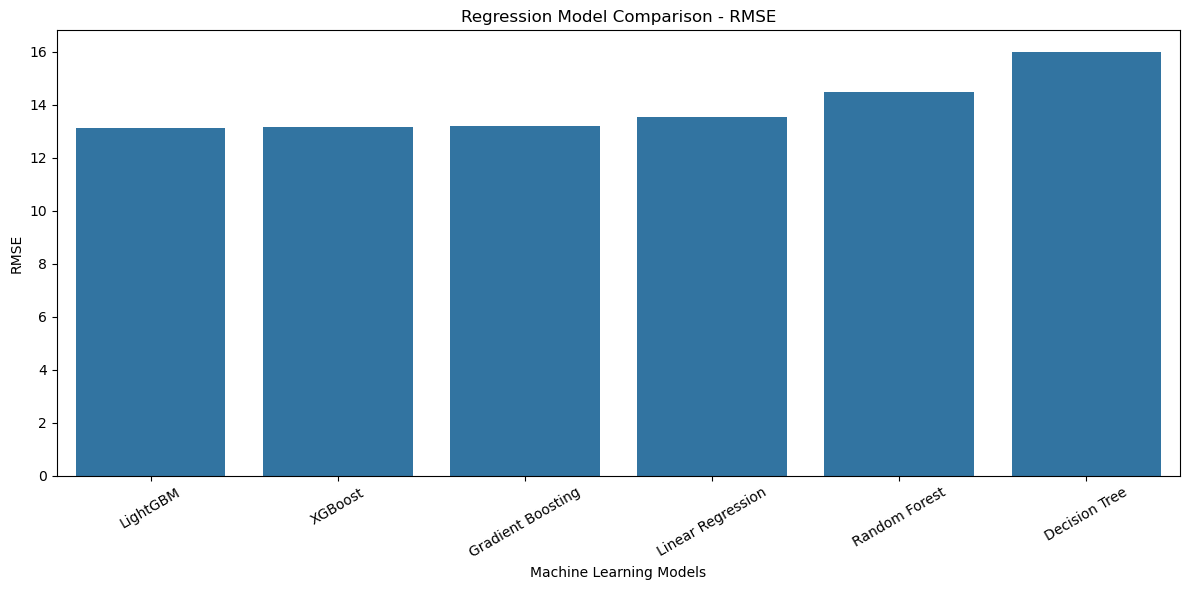

In [36]:
# Visualise model performance

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("Regression Model Comparison - RMSE")

plt.xlabel("Machine Learning Models")

plt.ylabel("RMSE")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

In [37]:
# Saving the regression model

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_pipelines[best_model_name]

import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    best_model,
    "models/regression_pipeline.joblib"
)

print("Best Regression Model:", best_model_name)

print("Model saved successfully!")


Best Regression Model: LightGBM
Model saved successfully!


In [38]:
import os

os.makedirs("models", exist_ok=True)

results_df.to_csv(
    "models/regression_model_comparison.csv",
    index=False
)

print("Regression comparison results saved successfully!")

Regression comparison results saved successfully!
